# Jagran Lakecity University
## Faculty of Science and Technology
### BTech CSE

---

## Practical Record: Assignment 1 - Module 1
### **Practical 2: Triangular, Trapezoidal, and Gaussian Membership Functions**

| Academic Details | Information |
| :--- | :--- |
| **Course** | Soft Computing |
| **Module** | Module I: Fuzzy Logic and Systems |
| **Student Name** | *Abhay Dwivedi* |
| **Enrollment No.** | *2023BTCSE002* |
| **Academic Session** | 2026 – 2027 |

---

### 1. Aim
To create and plot Triangular, Trapezoidal, and Gaussian membership functions using Python and scikit-fuzzy.

### 2. Theory: Structural Geometries of Fuzzy Membership Functions

A membership function provides the mathematical mapping between crisp real-world measurements and fuzzy truth values.

#### 1. Triangular Membership Geometry ($\text{trimf}$):
Parametrized by vector $[a, b, c]$:
$$\mu(x) = \max\left(0, \min\left(\frac{x - a}{b - a}, \frac{c - x}{c - b}\right)\right)$$
- Features a single point apex $b$ where $\mu(b) = 1.0$.

#### 2. Trapezoidal Membership Geometry ($\text{trapmf}$):
Parametrized by vector $[a, b, c, d]$:
$$\mu(x) = \max\left(0, \min\left(\frac{x - a}{b - a}, 1, \frac{d - x}{d - c}\right)\right)$$
- Features an extended core plateau $[b, c]$ suitable for tolerance ranges.

#### 3. Gaussian Membership Geometry ($\text{gaussmf}$):
Parametrized by mean center $c$ and standard deviation $\sigma$:
$$\mu(x) = \exp\left(-\frac{1}{2}\left(\frac{x - c}{\sigma}\right)^2\right)$$
- Features non-zero asymptotic tails and continuous derivatives $\frac{d\mu}{dx}$ everywhere.

### 3. Step 1: Implementation of MFs Over an Industrial Pressure Universe

#### What this cell does:
We define an industrial pressure scale $p \in [0, 120]$ PSI with 600 resolution points.
We generate:
- Triangular MF: $[25, 60, 95]$ PSI
- Trapezoidal MF: $[20, 40, 80, 100]$ PSI
- Gaussian MF: $c = 60, \sigma = 18$ PSI
We cross-verify `skfuzzy` against pure vectorized NumPy functions.

In [8]:
import numpy as np
import skfuzzy as fuzz

# Universe: Pressure in PSI [0, 120]
p_universe = np.linspace(0, 120, 601)

# Topologies parameters
tri_args = [25, 60, 95]
trap_args = [20, 40, 80, 100]
gauss_center = 60.0
gauss_width = 18.0

# Generate using scikit-fuzzy
tri_pressure = fuzz.trimf(p_universe, tri_args)
trap_pressure = fuzz.trapmf(p_universe, trap_args)
gauss_pressure = fuzz.gaussmf(p_universe, gauss_center, gauss_width)

# Vectorized manual check for Gaussian
gauss_manual = np.exp(-0.5 * ((p_universe - gauss_center) / gauss_width) ** 2)
gauss_error = np.max(np.abs(gauss_pressure - gauss_manual))

print("Membership functions for Pressure Universe created successfully.")
print(f"Discrepancy between scikit-fuzzy and NumPy formulation: {gauss_error:.2e}")


Membership functions for Pressure Universe created successfully.
Discrepancy between scikit-fuzzy and NumPy formulation: 1.11e-16


### 4. Step 2: Probing Membership Across Diverse Operating Pressures

#### What this cell does:
We probe each membership function at specific benchmark pressures: $p = 20, 40, 60, 80, 100, 115$ PSI to evaluate response profiles.

In [6]:
probe_pressures = [20.0, 40.0, 60.0, 80.0, 100.0, 115.0]

print("=" * 72)
print("             PRESSURE MEMBERSHIP FUNCTION PROBE AUDIT")
print("=" * 72)
print(f"{'Pressure (PSI)':<16} | {'Triangular':<15} | {'Trapezoidal':<15} | {'Gaussian':<15}")
print("-" * 72)

for p in probe_pressures:
    val_tri = fuzz.interp_membership(p_universe, tri_pressure, p)
    val_trap = fuzz.interp_membership(p_universe, trap_pressure, p)
    val_gauss = fuzz.interp_membership(p_universe, gauss_pressure, p)
    print(f"{p:<16.1f} | {val_tri:<15.4f} | {val_trap:<15.4f} | {val_gauss:<15.4f}")

print("=" * 72)


             PRESSURE MEMBERSHIP FUNCTION PROBE AUDIT
Pressure (PSI)   | Triangular      | Trapezoidal     | Gaussian       
------------------------------------------------------------------------
20.0             | 0.0000          | 0.0000          | 0.0847         
40.0             | 0.4286          | 1.0000          | 0.5394         
60.0             | 1.0000          | 1.0000          | 1.0000         
80.0             | 0.4286          | 1.0000          | 0.5394         
100.0            | 0.0000          | 0.0000          | 0.0847         
115.0            | 0.0000          | 0.0000          | 0.0094         


### 5. Step 3: Graphical Visualization with Annotated Core Geometries

#### What this cell does:
We plot the three functions using a distinct color theme (Steel Blue, Vivid Orange, Slate Purple) with filled contours and apex/plateau annotations.

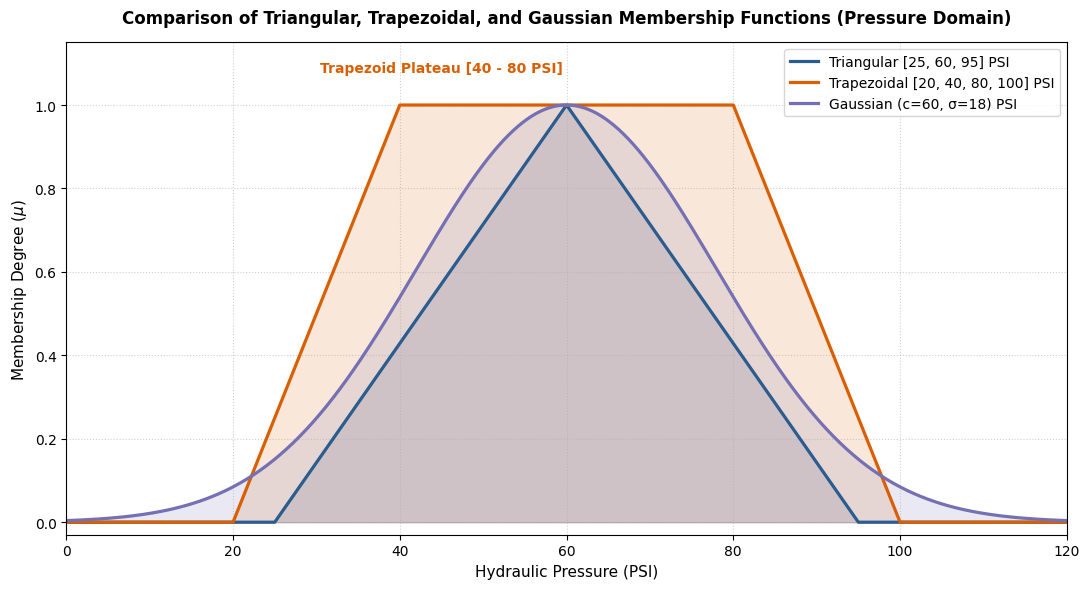

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

# Plot Triangular
plt.plot(p_universe, tri_pressure, color='#2b5c8f', linewidth=2.3, label='Triangular [25, 60, 95] PSI')
plt.fill_between(p_universe, tri_pressure, color='#2b5c8f', alpha=0.15)

# Plot Trapezoidal
plt.plot(p_universe, trap_pressure, color='#d95f02', linewidth=2.3, label='Trapezoidal [20, 40, 80, 100] PSI')
plt.fill_between(p_universe, trap_pressure, color='#d95f02', alpha=0.15)

# Plot Gaussian
plt.plot(p_universe, gauss_pressure, color='#7570b3', linewidth=2.3, label='Gaussian (c=60, σ=18) PSI')
plt.fill_between(p_universe, gauss_pressure, color='#7570b3', alpha=0.15)

# Annotations
plt.annotate('Trapezoid Plateau [40 - 80 PSI]', xy=(60, 1.0), xytext=(45, 1.08),
             ha='center', fontsize=10, fontweight='bold', color='#d95f02')

plt.title('Comparison of Triangular, Trapezoidal, and Gaussian Membership Functions (Pressure Domain)',
          fontsize=12, fontweight='bold', pad=14)
plt.xlabel('Hydraulic Pressure (PSI)', fontsize=11)
plt.ylabel(r'Membership Degree ($\mu$)', fontsize=11)
plt.xlim(0, 120)
plt.ylim(-0.03, 1.15)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


### 6. Results and Key Observations

| Geometric Topology | Parameters | Core Characteristic | Gradient Properties | Practical Utility |
| :---: | :---: | :---: | :---: | :--- |
| **Triangular** | $[25, 60, 95]$ | Singleton $\{60\}$ | Piecewise constant slopes | Fast real-time embedded control |
| **Trapezoidal** | $[20, 40, 80, 100]$ | Range $[40, 80]$ | Constant slopes with flat plateau | Operating safe-tolerance bands |
| **Gaussian** | $c=60, \sigma=18$ | Singleton $\{60\}$ | Smooth continuous derivative everywhere | Gradient descent neuro-fuzzy optimization |

#### Key Observations in Simple Words:
1. **Plateau vs. Peak:** At $p = 40$ PSI and $p = 80$ PSI, the trapezoidal function delivers full membership ($\mu = 1.0$), while the triangular function yields only $\mu = 0.43$.
2. **Smooth Decay:** The Gaussian function decays gradually, maintaining $\mu = 0.009$ even at $p = 115$ PSI, whereas triangular and trapezoidal functions drop to exact zero.
3. **Engineering Trade-off:** Triangular and trapezoidal functions require only addition and comparison, whereas Gaussian evaluation involves floating-point exponentiation.

---
### 7. Conclusion
1. We successfully generated Triangular, Trapezoidal, and Gaussian membership functions in Python using `scikit-fuzzy`.
2. We audited numerical outputs against vectorized NumPy formulations.
3. We visually analyzed the differences in modal cores, support bands, and slope smoothness.